# Unsupervised Tasks: Bike Trip and Stations Profiles

In [411]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [412]:
df_bikes = pd.read_csv("../csv/bikes.csv")
df_bike_types = pd.read_csv("../csv/bike_types.csv")
df_stations = pd.read_csv("../csv/stations.csv")
df_cities = pd.read_csv("../csv/cities.csv")
df_stations_status = pd.read_csv("../csv/stations_status.csv")
df_trips_small = pd.read_csv("../csv/trips_small.csv")

# 1.1 Bikes

In [413]:
df_bikes.head()

,id,bike_type_id,computer_id
0,400481,196,83300002927
1,374044,204,7551171765
2,373778,204,7551140444
3,34749,14,0
4,88359,143,7551052355


# 1.2 bike_types

In [414]:
df_bike_types.head()

,id,vehicle_image,name,description,form_factor,rider_capacity,propulsion_type,max_range,battery_capacity
0,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [415]:
df_bike_types.shape

(121, 9)

In [416]:
df_bike_types.info()

<class 'pandas.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                121 non-null    int64  
 1   vehicle_image     91 non-null     str    
 2   name              91 non-null     str    
 3   description       51 non-null     str    
 4   form_factor       91 non-null     str    
 5   rider_capacity    91 non-null     float64
 6   propulsion_type   91 non-null     str    
 7   max_range         15 non-null     float64
 8   battery_capacity  22 non-null     float64
dtypes: float64(3), int64(1), str(5)
memory usage: 25.7 KB


In [417]:
df_bike_types.dtypes

id                    int64
vehicle_image           str
name                    str
description             str
form_factor             str
rider_capacity      float64
propulsion_type         str
max_range           float64
battery_capacity    float64
dtype: object

In [418]:
df_bike_types.describe()

,id,rider_capacity,max_range,battery_capacity
count,121.000000,91.000000,15.0,22.000000
mean,134.454545,1.230769,60000.0,547.727273
std,77.738450,0.423659,0.0,61.638873
min,0.000000,1.000000,60000.0,500.000000
25%,72.000000,1.000000,60000.0,500.000000
50%,149.000000,1.000000,60000.0,500.000000
75%,201.000000,1.000000,60000.0,600.000000
max,254.000000,2.000000,60000.0,690.000000


In [419]:
print("Nombre de doublons : ", df_bike_types.duplicated().sum(), "\n")

Nombre de doublons :  0 



In [420]:
len(df_bike_types["name"].unique())

47

In [421]:
df_bike_types["name"].unique()

<ArrowStringArray>
[                              nan,                         'Comfort',
   'Rower z fotelikiem dziecięcym',                          'Tandem',
                 'Elektricno kolo',                     'e-CARGObike',
            'Rowerek dziecięcy 6+',     '3-rychlostní SMARTbike 2.0.',
       'e-SMARTbike 2.0 with RFID',         '28 Zoll - Tourenfahrrad',
                'e-SMARTbike 2.0.',          'Smartbike 2.0 (B) 2019',
                 'e-SMARTbike 1.0',                       'UsedomRad',
               'UsedomRad Classic',         '20 Zoll - Kinderfahrrad',
         '24 Zoll - Kinderfahrrad',                 'Z wałem kardana',
          '7-rychlostní SMARTbike',                 'e-Bike "LaBigi"',
                          'E-Bike',     '7-rychlostní SMARTbike 2.0.',
                     'e-Cargobike',                       'CARGObike',
     '8-rychlostní SMARTbike 2.0.',                  'with Framelock',
          '8-rychlostní SMARTbike',            'CARGObike 

In [422]:
# Pour les lignes NaN, voir comment elles sont utilisées dans les autres dataset :
# On regarde la dépendance avec le dataframe bikes
# Prend un id de bike_type où la ligne est NaN dans le dataframe pour voir à quoi ça ressembe
df_bikes[df_bikes['bike_type_id'] == 152]

,id,bike_type_id,computer_id
506,68228,152,0
507,67230,152,0
508,67297,152,0
696,68408,152,0
764,66018,152,0
...,...,...,...
28182,68470,152,0
28183,68905,152,0
28184,67330,152,0
28677,68095,152,0


In [423]:
# Les éléments de bikes qui ont un bike_type où la ligne est NaN dans bike_types n'apportent pas beaucoup d'info
# On regarde le dataframe trips_small pour voir comment ils sont utilisés
df_trips_small[df_trips_small["bike_id"] == 67257]

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
400108,67257,620,1.666766e+09,16.882574,52.343290,16.902992,52.372152,14043132.0,373709.0,NaN,NaN,1080.0,3496.042754
400109,67257,394,1.666974e+09,16.886571,52.353718,16.902992,52.372152,4328771.0,373709.0,NaN,NaN,840.0,2333.415628


<Axes: xlabel='name'>

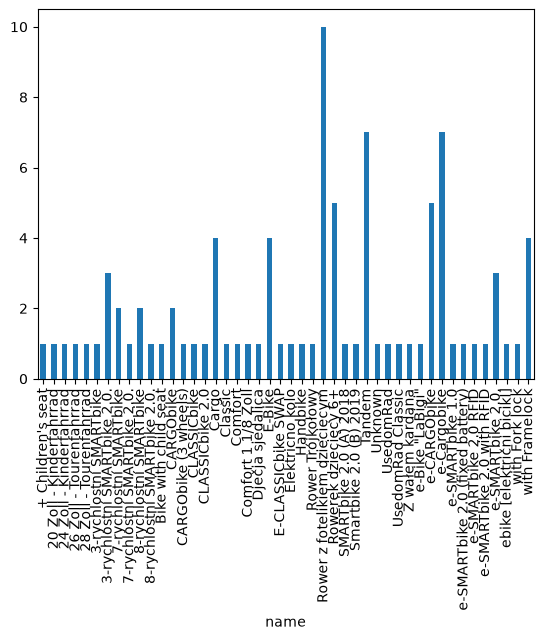

In [424]:
df_bike_types.groupby('name')["name"].count().plot(kind="bar")

In [425]:
df_bike_types["propulsion_type"].unique()

<ArrowStringArray>
[nan, 'human', 'electric_assist']
Length: 3, dtype: str

In [426]:
propulsion = df_bike_types.groupby('propulsion_type')["propulsion_type"].count()
propulsion

propulsion_type
electric_assist    27
human              64
Name: propulsion_type, dtype: int64

<Axes: >

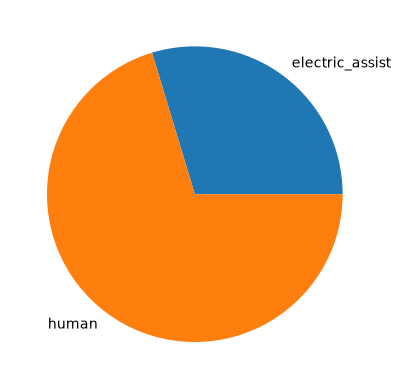

In [427]:
propulsion.plot(kind="pie")

In [428]:
df_bike_types["form_factor"].unique()

<ArrowStringArray>
[nan, 'bicycle', 'cargo_bicycle', 'other']
Length: 4, dtype: str

In [429]:
grouped_form = df_bike_types.groupby("form_factor").size().reset_index(name = "count")
grouped_form

,form_factor,count
0,bicycle,71
1,cargo_bicycle,19
2,other,1


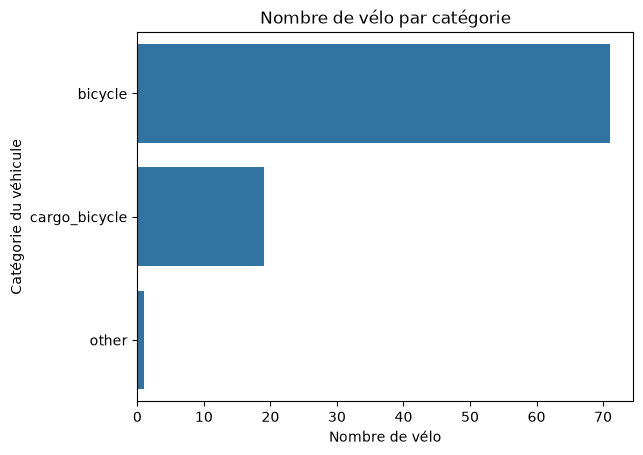

In [430]:
grouped_form = grouped_form.sort_values(["count"], ascending=False)

plt.figure()
sns_barplot = sns.barplot(grouped_form, x="count", y="form_factor")
sns_barplot.set(
    title = "Nombre de vélo par catégorie",
    xlabel = "Nombre de vélo",
    ylabel = "Catégorie du véhicule"
)
plt.show()

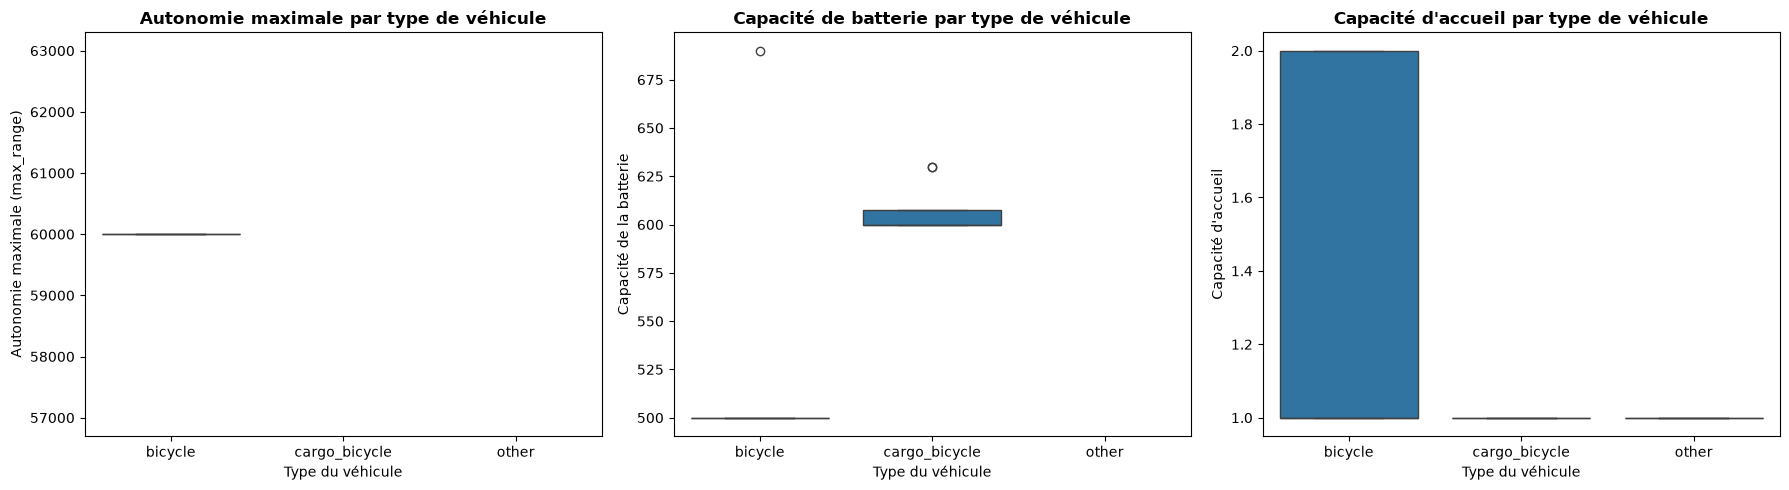

In [431]:
# Par form_factor
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Max_Range
sns.boxplot(data=df_bike_types, x='form_factor', y='max_range', ax=axes[0])
axes[0].set_title("Autonomie maximale par type de véhicule", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Type du véhicule", fontsize=10)
axes[0].set_ylabel("Autonomie maximale (max_range)", fontsize=10)

# Battery_Capacity
sns.boxplot(data=df_bike_types, x='form_factor', y='battery_capacity', ax=axes[1])
axes[1].set_title("Capacité de batterie par type de véhicule", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Type du véhicule", fontsize=10)
axes[1].set_ylabel("Capacité de la batterie", fontsize=10)

# Rider_Capacity
sns.boxplot(data=df_bike_types, x='form_factor', y='rider_capacity', ax=axes[2])
axes[2].set_title("Capacité d'accueil par type de véhicule", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Type du véhicule", fontsize=10)
axes[2].set_ylabel("Capacité d'accueil", fontsize=10)

plt.tight_layout()
plt.show()

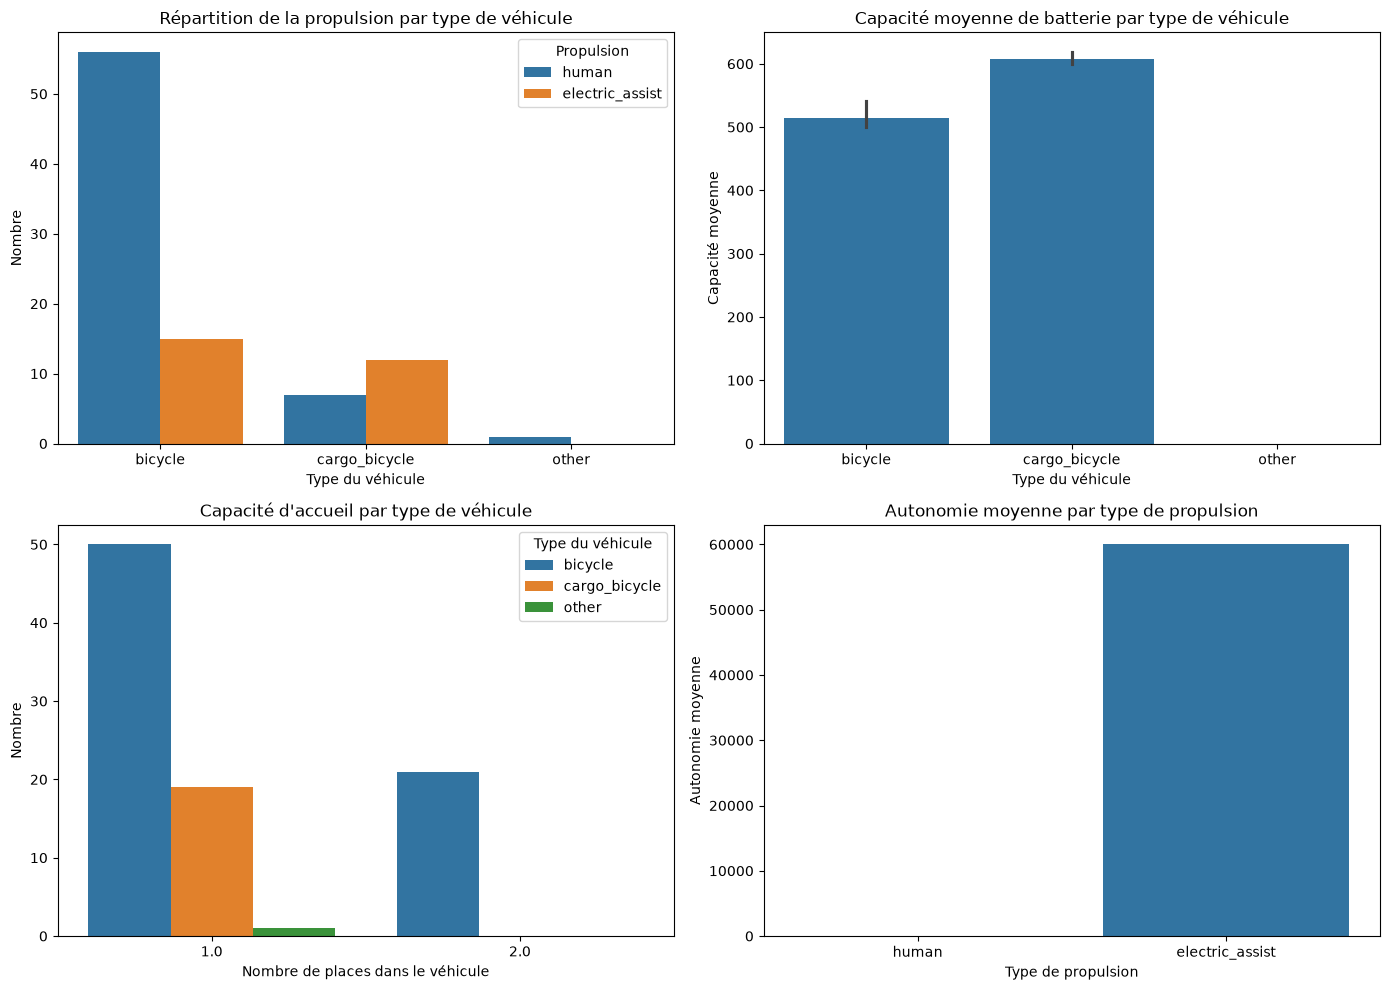

In [433]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df_bike_types, x='form_factor', hue='propulsion_type', ax=axes[0, 0])
axes[0, 0].set_title("Répartition de la propulsion par type de véhicule")
axes[0, 0].set_xlabel("Type du véhicule")
axes[0, 0].set_ylabel("Nombre")
axes[0, 0].legend(title="Propulsion")

sns.barplot(data=df_bike_types, x='form_factor', y='battery_capacity', estimator='mean', ax=axes[0, 1])
axes[0, 1].set_title("Capacité moyenne de batterie par type de véhicule")
axes[0, 1].set_xlabel("Type du véhicule")
axes[0, 1].set_ylabel("Capacité moyenne")

sns.countplot(data=df_bike_types, x='rider_capacity', hue='form_factor', ax=axes[1, 0])
axes[1, 0].set_title("Capacité d'accueil par type de véhicule")
axes[1, 0].set_xlabel("Nombre de places dans le véhicule")
axes[1, 0].set_ylabel("Nombre")
axes[1, 0].legend(title="Type du véhicule")

sns.barplot(data=df_bike_types, x='propulsion_type', y='max_range', estimator='mean', ax=axes[1, 1])
axes[1, 1].set_title("Autonomie moyenne par type de propulsion")
axes[1, 1].set_xlabel("Type de propulsion")
axes[1, 1].set_ylabel("Autonomie moyenne")

plt.tight_layout()
plt.show()

# 1.3 Stations 

In [ ]:
df_stations.head()

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat
0,142186362,135,BIKE 500100,0,NaN,12,0,0,NaN,7.821669,51.677449
1,940986,176,Bahnhof Trassenmoor 5525,5525,NaN,0,6,0,NaN,13.868973,54.090538
2,93646685,176,Mutter/Vater-Kind-Kurklinik Haus Möwennest Zin...,5529,stele,0,15,0,NaN,13.918970,54.073088
3,111365509,243,Station Road,8494,smart_sign,0,20,0,NaN,-3.936120,56.119272
4,405835,302,Birkirkara Road,6868,sign,0,6,0,NaN,14.481456,35.906836


In [ ]:
df_stations.shape

(2932, 11)

In [ ]:
df_stations.info()
#Drop rack_locks column

<class 'pandas.DataFrame'>
RangeIndex: 2932 entries, 0 to 2931
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             2932 non-null   int64  
 1   city_id        2932 non-null   int64  
 2   name           2932 non-null   str    
 3   app_number     2932 non-null   int64  
 4   terminal_type  2345 non-null   str    
 5   place_type     2932 non-null   int64  
 6   bike_racks     2932 non-null   int64  
 7   special_racks  2932 non-null   int64  
 8   rack_locks     0 non-null      float64
 9   lon            2932 non-null   float64
 10  lat            2932 non-null   float64
dtypes: float64(3), int64(6), str(2)
memory usage: 326.9 KB


In [ ]:
df_stations.describe()

,id,city_id,app_number,place_type,bike_racks,special_racks,rack_locks,lon,lat
count,2.932000e+03,2932.000000,2932.000000,2932.000000,2932.000000,2932.000000,0.0,2932.000000,2932.000000
mean,4.116020e+07,480.171555,29985.929400,3.760914,6.033424,-0.011255,NaN,13.172182,49.272772
std,4.773764e+07,242.781001,61868.290176,6.894175,6.495116,0.486820,NaN,6.914270,4.342509
min,9.400000e+01,7.000000,0.000000,0.000000,0.000000,-10.000000,NaN,-15.758277,7.745476
25%,3.604443e+06,251.000000,4918.750000,0.000000,0.000000,0.000000,NaN,8.156823,47.955417
50%,2.531790e+07,527.000000,7907.500000,0.000000,6.000000,0.000000,NaN,14.314387,50.290478
75%,5.661078e+07,702.000000,48798.250000,0.000000,10.000000,0.000000,NaN,17.488668,51.602447
max,2.192360e+08,858.000000,999574.000000,27.000000,70.000000,12.000000,NaN,33.413632,57.005195


In [ ]:
df_stations = df_stations.drop('rack_locks', axis= 1)

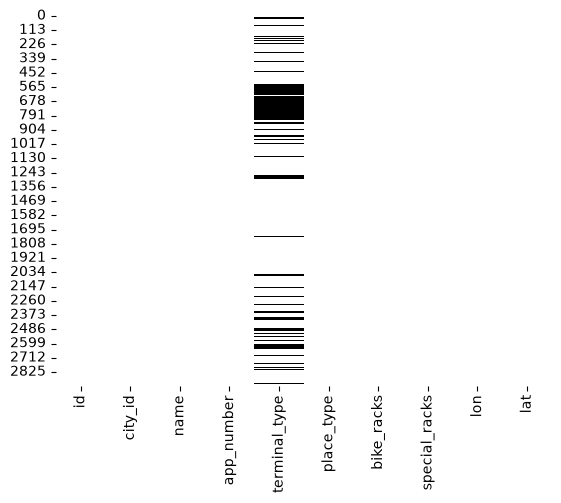

In [ ]:
sns.heatmap(df_stations.isna(), cbar=False, cmap='binary')
plt.show()

In [ ]:
df_stations["city_id"].unique()

array([135, 176, 243, 302, 729, 629, 184, 833, 134, 767, 431, 281, 174,
       639, 620, 557, 713,  64, 710, 394, 717, 630, 712, 142, 794,   7,
       383, 320, 519, 747, 137, 759, 212, 775, 711, 648,  88, 689, 749,
       442, 688, 768, 463, 469, 634, 251, 518, 570, 331, 548, 128, 817,
       680, 523, 624, 643, 754, 530, 858, 477, 567, 497, 138, 146, 185,
       632, 206, 327, 396, 592, 505, 835, 143, 144, 149, 156, 165, 213,
       395, 414, 323, 388, 391, 464, 465, 492, 716, 131, 734, 136, 220,
       621, 627, 633, 635, 796, 248, 255, 278, 332, 382, 392, 448, 480,
       482, 537, 558, 559, 560, 678, 684, 305, 798, 301, 324, 745, 411,
       413,  23, 421, 415, 422, 723, 429, 739, 446, 452, 461, 679, 486,
       496, 504, 527, 545, 535, 555, 644, 683, 550, 551, 562, 563, 564,
       565, 566, 568, 569, 571, 638, 675, 445, 740, 741, 802, 804, 752,
       736, 676, 160, 155, 704, 702, 706, 708, 725, 727, 774, 776, 769,
       780, 807, 808, 819, 848, 853, 856, 831, 810, 811, 308, 17

In [ ]:
len(df_stations["city_id"].unique())

185

In [ ]:
df_stations["app_number"].unique()

array([    0,  5525,  5529, ..., 30024,  3586, 51312], shape=(2914,))

In [ ]:
df_stations["terminal_type"].unique()

<ArrowStringArray>
[             nan,          'stele',     'smart_sign',           'sign',
          '7inch',           'free',      'character',   'traffic_sign',
            'mmt', 'terminal_sleek',           'pult']
Length: 11, dtype: str

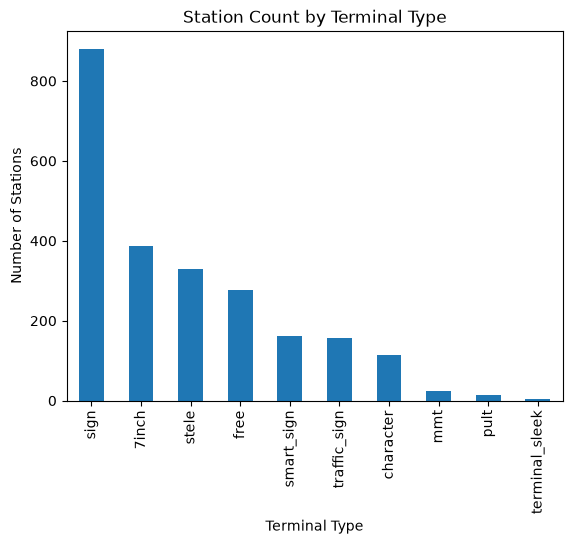

In [ ]:
# 1. Get exact value counts as a table
df_stations['terminal_type'].value_counts()

# 2. Get percentage distribution across hardware types[cite: 5]
df_stations['terminal_type'].value_counts(normalize=True) * 100

# 3. Quick Pandas vertical bar chart
df_stations['terminal_type'].value_counts().plot(
    kind='bar',
    xlabel='Terminal Type',
    ylabel='Number of Stations',
    title='Station Count by Terminal Type'
)
plt.show()

# 1.4 cities

In [ ]:
df_cities.head()

,id,name,lat,lon,timezone,country,return_to_official_only
0,220,Zagreb,45.7984,15.98810,Europe/Berlin,HR,True
1,431,Kalisz,51.7525,18.03410,Europe/Warsaw,PL,True
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True
3,519,Siemianowice Śląskie,50.3031,19.02220,Europe/Warsaw,PL,True
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False


In [ ]:
df_cities.shape

(267, 7)

In [ ]:
df_cities.info()

<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       267 non-null    int64  
 1   name                     267 non-null    str    
 2   lat                      267 non-null    float64
 3   lon                      267 non-null    float64
 4   timezone                 267 non-null    str    
 5   country                  267 non-null    str    
 6   return_to_official_only  267 non-null    bool   
dtypes: bool(1), float64(2), int64(1), str(3)
memory usage: 19.5 KB


In [ ]:
df_cities.describe()

,id,lat,lon
count,267.000000,267.000000,267.000000
mean,496.985019,49.067596,12.154192
std,232.772760,4.155125,7.029840
min,1.000000,27.815400,-15.518200
25%,314.000000,47.827850,8.306550
50%,537.000000,49.898000,13.744600
75%,691.500000,51.589750,16.831200
max,858.000000,57.690200,33.453500


In [ ]:
len(df_cities["name"].unique())

267

In [ ]:
# Nombre de fuseaux horaires
df_cities["timezone"].nunique()

9

In [ ]:
df_cities["country"].unique()

<ArrowStringArray>
['HR', 'PL', 'AT', 'DE', 'MT', 'GB', 'CH', 'CZ', 'CY', 'ES', 'SI', 'SK', 'SE',
 'IT', 'LV']
Length: 15, dtype: str

In [ ]:
# Nombre de villes par pays
df_cities["country"].value_counts()

country
DE    91
PL    53
CZ    25
AT    24
HR    19
ES    16
CH    13
SI    10
GB     9
CY     2
MT     1
SK     1
SE     1
IT     1
LV     1
Name: count, dtype: int64

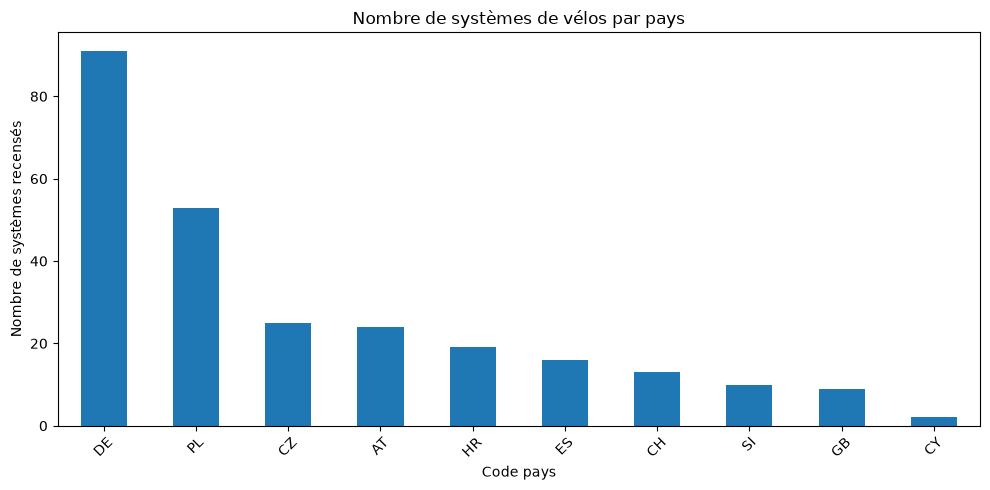

In [ ]:
# Visualisation
df_cities["country"].value_counts().head(10).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Nombre de systèmes de vélos par pays")
plt.xlabel("Code pays")
plt.ylabel("Nombre de systèmes recensés")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
df_cities["return_to_official_only"].unique()

array([ True, False])

In [ ]:
official_only = df_cities.groupby("return_to_official_only")["return_to_official_only"].count()
official_only

return_to_official_only
False     67
True     200
Name: return_to_official_only, dtype: int64

<Axes: >

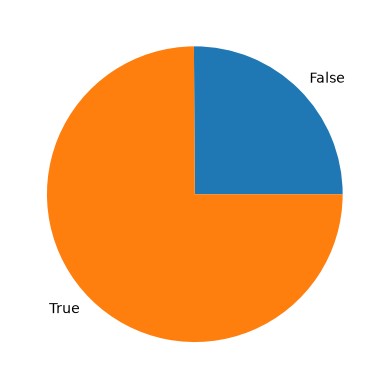

In [ ]:
official_only.plot(kind='pie')

# 1.5 stations status

In [ ]:
df_stations_status.head()

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
0,101896428,1.661530e+09,2,0,2,0,0,False
1,54643,1.661531e+09,1,0,1,0,0,False
2,6201611,1.661531e+09,3,0,3,0,0,False
3,294346,1.661531e+09,8,0,8,0,0,False
4,781866,1.661531e+09,1,1,0,5,0,False


In [ ]:
df_stations_status.info()

<class 'pandas.DataFrame'>
RangeIndex: 2925967 entries, 0 to 2925966
Data columns (total 8 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   station_id               int64  
 1   time                     float64
 2   bikes                    int64  
 3   booked_bikes             int64  
 4   bikes_available_to_rent  int64  
 5   free_racks               int64  
 6   free_special_racks       int64  
 7   maintenance              bool   
dtypes: bool(1), float64(1), int64(6)
memory usage: 159.1 MB


In [ ]:
# 1. Convert numeric UTC timestamp (seconds) to UTC datetime
df_stations_status['datetime'] = pd.to_datetime(df_stations_status['time'], unit='s', utc=True)

# 2. Extract separate numeric day and hour columns
df_stations_status['day_of_month'] = df_stations_status['datetime'].dt.day         # 1 to 31
df_stations_status['day_of_week']  = df_stations_status['datetime'].dt.day_name()   # e.g., 'Monday'
df_stations_status['hour']         = df_stations_status['datetime'].dt.hour       # 0 to 23

df_stations_status.head(10)

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,datetime,day_of_month,day_of_week,hour
0,101896428,1.661530e+09,2,0,2,0,0,False,2022-08-26 16:14:01+00:00,26,Friday,16
1,54643,1.661531e+09,1,0,1,0,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
2,6201611,1.661531e+09,3,0,3,0,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
3,294346,1.661531e+09,8,0,8,0,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
4,781866,1.661531e+09,1,1,0,5,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
5,137700,1.661531e+09,15,0,15,1,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
6,50464,1.661531e+09,3,0,3,3,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
7,6290772,1.661531e+09,3,0,3,1,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
8,8341045,1.661531e+09,10,0,10,0,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
9,3581060,1.661531e+09,7,0,7,8,6,False,2022-08-26 16:15:01+00:00,26,Friday,16


# 1.6 trips small

In [ ]:
df_trips_small.head()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993


In [ ]:
df_trips_small.shape

(1161376, 13)

In [ ]:
df_trips_small.info()
#Drop battery_start, battery_end

<class 'pandas.DataFrame'>
RangeIndex: 1161376 entries, 0 to 1161375
Data columns (total 13 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   bike_id           1161376 non-null  int64  
 1   city_id           1161376 non-null  int64  
 2   time_start        1161376 non-null  float64
 3   lon_start         1161376 non-null  float64
 4   lat_start         1161376 non-null  float64
 5   lon_end           1161376 non-null  float64
 6   lat_end           1161376 non-null  float64
 7   station_id_start  1072161 non-null  float64
 8   station_id_end    1039472 non-null  float64
 9   battery_start     168532 non-null   float64
 10  battery_end       168641 non-null   float64
 11  duration          1161376 non-null  float64
 12  distance          1161376 non-null  float64
dtypes: float64(11), int64(2)
memory usage: 115.2 MB


In [ ]:
df_trips_small.drop(["battery_start", "battery_end"], axis=1)

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,duration,distance
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,360.0,135.879806
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,1920.0,3301.514764
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,780.0,115.020620
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,540.0,1643.609250
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,4680.0,897.351993
...,...,...,...,...,...,...,...,...,...,...,...
1161371,840054,679,1.684753e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,1320.0,3061.891906
1161372,840054,679,1.685088e+09,-3.166644,51.446057,-3.163247,51.465538,6270602.0,88102363.0,780.0,2178.941052
1161373,840054,679,1.686059e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,900.0,3061.891906
1161374,840054,679,1.686121e+09,-3.185756,51.429879,-3.163247,51.465538,86312067.0,88102363.0,1020.0,4260.899309


In [ ]:
df_trips_small.describe()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
count,1.161376e+06,1.161376e+06,1.161376e+06,1.161376e+06,1.161376e+06,1.161376e+06,1.161376e+06,1.072161e+06,1.039472e+06,168532.000000,168641.000000,1.161376e+06,1.161376e+06
mean,2.265793e+05,5.179235e+02,1.676599e+09,1.143184e+01,4.941432e+01,1.143162e+01,4.941407e+01,4.223439e+07,4.236450e+07,80.988697,76.688996,1.256241e+03,1.791774e+03
std,1.996392e+05,2.374043e+02,9.407677e+06,7.320269e+00,3.707710e+00,7.320443e+00,3.708131e+00,4.759018e+07,4.793164e+07,21.384192,22.615122,1.980838e+03,1.495191e+03
min,3.346000e+03,7.000000e+00,1.661525e+09,-1.560567e+01,2.774058e+01,-1.560567e+01,2.774058e+01,9.400000e+01,9.400000e+01,0.000000,0.000000,1.210000e+02,5.001365e+01
25%,5.962500e+04,3.310000e+02,1.666845e+09,7.165686e+00,4.717771e+01,7.165686e+00,4.717771e+01,5.669128e+06,5.445517e+06,66.000000,61.000000,4.800000e+02,8.851685e+02
50%,8.881000e+04,5.480000e+02,1.678902e+09,1.019364e+01,5.027373e+01,1.018726e+01,5.026997e+01,2.072905e+07,1.982877e+07,89.000000,83.000000,7.200000e+02,1.346711e+03
75%,4.001430e+05,7.170000e+02,1.685627e+09,1.745811e+01,5.174006e+01,1.745811e+01,5.173991e+01,7.251972e+07,7.279031e+07,100.000000,97.000000,1.200000e+03,2.238540e+03
max,8.400540e+05,8.580000e+02,1.689458e+09,3.398531e+01,5.708158e+01,3.398632e+01,5.708158e+01,2.192360e+08,2.146129e+08,100.000000,100.000000,2.874000e+04,1.999946e+04


# 2. Merge tables

In [434]:
# On rassemble les trois dataframe (bike_types, bikes, et trips_small) car tous reliés entre eux
bike_sub = df_bikes[['id', 'bike_type_id']]
bike_type_sub = df_bike_types[['id', 'name', 'form_factor', 'propulsion_type', 'max_range', "battery_capacity"]]

trips_with_bikes = pd.merge(df_trips_small, bike_sub, left_on='bike_id', right_on='id', how='left')
complete_df = pd.merge(trips_with_bikes, bike_type_sub, left_on="bike_type_id", right_on="id", how="left")
complete_df = complete_df.drop(columns=['id_x', 'id_y'])

complete_df

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance,bike_type_id,name,form_factor,propulsion_type,max_range,battery_capacity
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806,15,with Fork lock,bicycle,human,NaN,NaN
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764,15,with Fork lock,bicycle,human,NaN,NaN
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620,15,with Fork lock,bicycle,human,NaN,NaN
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250,15,with Fork lock,bicycle,human,NaN,NaN
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993,15,with Fork lock,bicycle,human,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1161371,840054,679,1.684753e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,96.0,1320.0,3061.891906,182,e-SMARTbike 2.0 with RFID,bicycle,electric_assist,60000.0,500.0
1161372,840054,679,1.685088e+09,-3.166644,51.446057,-3.163247,51.465538,6270602.0,88102363.0,100.0,97.0,780.0,2178.941052,182,e-SMARTbike 2.0 with RFID,bicycle,electric_assist,60000.0,500.0
1161373,840054,679,1.686059e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,95.0,900.0,3061.891906,182,e-SMARTbike 2.0 with RFID,bicycle,electric_assist,60000.0,500.0
1161374,840054,679,1.686121e+09,-3.185756,51.429879,-3.163247,51.465538,86312067.0,88102363.0,87.0,75.0,1020.0,4260.899309,182,e-SMARTbike 2.0 with RFID,bicycle,electric_assist,60000.0,500.0


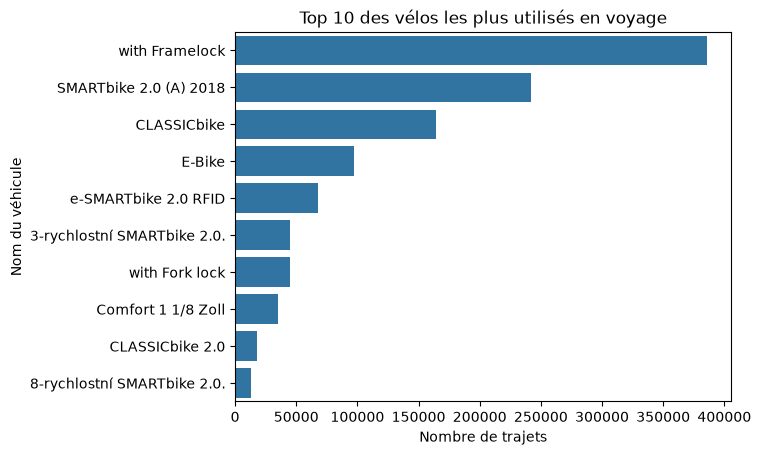

In [435]:
top_bikes = complete_df['name'].value_counts().head(10).reset_index()
top_bikes.columns = ['name', 'count']

plt.figure()
top_bikes_barplot = sns.barplot(data=top_bikes, x='count', y='name')
top_bikes_barplot.set_title("Top 10 des vélos les plus utilisés en voyage")
top_bikes_barplot.set_xlabel("Nombre de trajets")
top_bikes_barplot.set_ylabel("Nom du véhicule")
plt.show()

In [ ]:
form_counts = complete_df['form_factor'].value_counts().reset_index()
form_counts.columns = ['form_factor', 'count']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(data=form_counts, x='form_factor', y='count', ax=axes[0])
axes[0].set_title("Proportion des types de vélos (comptage)")
axes[0].set_xlabel("Facteur de forme")
axes[0].set_ylabel("Nombre de trajets")

complete_df['form_factor'].value_counts().plot(
    kind='pie', 
    autopct='%1.1f%%', 
    startangle=90, 
    ax=axes[1]
)
axes[1].set_title("Répartition en pourcentage")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()